# Continued pretraining of GPT-2 on PubMed

This notebook covers the first stage of the pipeline: **domain-adaptive pretraining** of GPT-2 on 100,000 open-access PubMed Central papers, before fine-tuning on MedText (`fpft.ipynb`).

```
pubmed-extractor/build_corpus.py   ->  raw corpus (JSONL, 20 MeSH strata x 5,000 papers)
src/corpus.py                      ->  decontaminated, cleaned, split, tokenized blocks
src/pretrain.py                    ->  GPT-2 continued pretraining  (this notebook)
src/train.py                       ->  fine-tuning on MedText        (fpft.ipynb)
```

The long training run is launched from a terminal (section 4), so it survives kernel restarts; the notebook prepares, checks and analyses it. Every run is tracked in MLflow (experiment `gpt2-pubmed-pretrain`).

In [2]:
import json
from pathlib import Path

import pandas as pd

from src.config import load_pretrain_config
from src.tracking import configure_tracking

config = load_pretrain_config("configs/gpt2_pubmed_pretrain.yaml")
configure_tracking(config)

## 1. Corpus preparation

`prepare_corpus()` (`src/corpus.py`) reads the raw JSONL shards without modifying them and:

1. **Decontaminates**: removes articles used by PubMedQA (`qiaojin/PubMedQA`, `pqa_labeled`), so the benchmark is not seen during pretraining.
2. **Cleans** the text: drops templated administrative sections (funding, ethics, author contributions, data availability, ...) and inline citation markers (`[1-3]`, `(Smith et al., 2020)`).
3. **Splits** 1% of the documents into a validation set, sampled within each MeSH stratum.
4. **Tokenizes** with the GPT-2 tokenizer, ends every document with `<|endoftext|>` and **packs** the tokens into blocks of 1,024.

The run below does nothing if `data/processed/pubmed_v1` already exists.

In [5]:
from src.corpus import prepare_corpus

prepare_corpus(config)

stats = json.loads((Path(config.corpus.processed_dir) / "stats.json").read_text())
pd.DataFrame(
    {
        "documents": {name: stats["documents"][name] for name in ("train", "validation")},
        "tokens": stats["tokens"],
        "blocks of 1,024": stats["blocks"],
    }
)

data/processed/pubmed_v1 already exists


,documents,tokens,"blocks of 1,024"
train,98999,619615627,605039
validation,1000,6345372,6188


In [3]:
print(f"Raw documents: {stats['documents']['raw']:,}")
print(f"Removed (in {stats['documents']['benchmark']}): {stats['documents']['removed_benchmark']}")
print(f"Text removed with administrative sections: {stats['cleaning']['removed_sections_pct']}%")
print(f"Text removed with citation markers: {stats['cleaning']['removed_citations_pct']}%")

Raw documents: 100,000
Removed (in qiaojin/PubMedQA/pqa_labeled): 1
Text removed with administrative sections: 0.89%
Text removed with citation markers: 0.81%


### What the model sees

A packed training block decoded back to text, around the boundary between two documents: the previous paper ends with `<|endoftext|>` and the next one starts with its title.

In [6]:
from transformers import AutoTokenizer
from src.corpus import load_pretrain_corpus

tokenizer = AutoTokenizer.from_pretrained(config.model.model_id)
corpus = load_pretrain_corpus(config.corpus.processed_dir)

block = next(
    row["input_ids"] for row in corpus["train"].select(range(200))
    if tokenizer.eos_token_id in row["input_ids"]
)
text = tokenizer.decode(block)
boundary = text.find(tokenizer.eos_token)
print(text[max(0, boundary - 300) : boundary + 300])

at Diosmin (∆Gbind of −38.19 ± 9.69 kcal·mol−1), and FAD (∆Gbind of −35.59 ± 7.65 kcal·mol−1) could be potential treatments against the E8 protein of the virus, which could decrease the transmission rate of this virus. Further experimental studies should be conducted to validate the current results.<|endoftext|>Absence of SARS-CoV-2 RNA in Peritoneal Fluid During Surgery in Pregnant Women Who Are COVID-19 Positive

## Study Objective

Coronavirus disease 2019 (COVID-19) infection poses significant risks during surgical interventions. We investigated the intraperitoneal presence of severe acute


## 2. Baseline: GPT-2 on PubMed

Validation loss and perplexity of the original GPT-2 on the held-out PubMed blocks. `evaluate_on_corpus()` uses the same blocks, batch size and precision as the evaluations during pretraining, so the numbers are directly comparable. The result is logged as an MLflow evaluation run (`stage=evaluate`).

In [5]:
from src.pretrain import evaluate_on_corpus
from src.tracking import log_evaluation

base_pubmed = evaluate_on_corpus(config.model.model_id, config)
log_evaluation(config.model.model_id, "pubmed_validation", base_pubmed, config)
base_pubmed

Loading weights: 100%|██████████| 148/148 [00:00<00:00, 26851.67it/s]
[transformers] `loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


Training Loss,Validation Loss,Step
No log,2.883543,0


2026/11/02 16:27:58 INFO mlflow.system_metrics.system_metrics_monitor: Started monitoring system metrics.
2026/11/02 16:27:58 INFO mlflow.system_metrics.system_metrics_monitor: Stopping system metrics monitoring...
2026/11/02 16:27:58 INFO mlflow.system_metrics.system_metrics_monitor: Successfully terminated system metrics monitoring!


{'loss': 2.8835434913635254, 'perplexity': 17.877509875946902}

## 3. Smoke test

A short run with the full configuration (20 optimizer steps of 512 blocks, about 10M tokens) checks the whole path: data loading, bf16 training with `torch.compile`, evaluation, checkpointing and MLflow logging. Smoke runs write to `checkpoints/pretrain/gpt2-pubmed-dapt-smoke`, always start fresh, are tagged `run_type=smoke` and are never registered.

In [7]:
from src.pretrain import run_pretraining

smoke = run_pretraining(config, max_steps=20)
smoke

Loading weights: 100%|██████████| 148/148 [00:00<00:00, 16984.70it/s]
2026/11/02 16:28:38 INFO mlflow.system_metrics.system_metrics_monitor: Started monitoring system metrics.
/home/hpc3/Documents/Projects/medllm-finetuning/.venv/lib/python3.11/site-packages/triton/knobs.py:504: UserWarning: TRITON_DEFAULT_FP_FUSION is unset: defaulting to FP fusion ENABLED for backward compatibility in Triton 3.9. The default will change to DISABLED in Triton 3.10; set TRITON_DEFAULT_FP_FUSION=1 to keep fusion enabled or =0 to adopt the new default early and silence this warning.
  warn_once(FP_FUSION_DEFAULT_WARNING)


Step,Training Loss,Validation Loss
20,2.992760,2.837138


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  3.40it/s]


Training Loss,Validation Loss,Step
2.992760,2.837138,20


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  3.36it/s]
2026/11/02 16:30:47 INFO mlflow.system_metrics.system_metrics_monitor: Stopping system metrics monitoring...
2026/11/02 16:30:47 INFO mlflow.system_metrics.system_metrics_monitor: Successfully terminated system metrics monitoring!


{'run_id': '55b2fe77bf6c4dd3b69172522427f5e2',
 'model_dir': 'checkpoints/pretrain/gpt2-pubmed-dapt-smoke/final',
 'eval_loss': 2.8371381759643555,
 'eval_perplexity': 17.06685325050477,
 'model_id': None}

### Learning-rate sweep

The peak learning rate trades adaptation for forgetting: a higher rate learns the PubMed domain faster but overwrites more of what GPT-2 already knows. `sweep_learning_rates()` runs one short pretraining per rate in `lr_sweep` (`5e-5`, `1e-4`, `3e-4`, 150 steps each, about 10 minutes per rate), each with its own cosine schedule, as nested MLflow runs under an `lr-sweep` run.

Short runs favour higher rates, because the full run decays over ~1,180 steps instead of 150. Use the table to rule out rates that are clearly worse, not to choose between close ones. The final model of each rate is kept, so it can also be evaluated on the fine-tuning dataset (forgetting check) once that dataset is set up.

Restart the kernel before this cell if an earlier training cell ran in it: PyTorch keeps the GPU memory it reserved.

In [5]:
from src.pretrain import sweep_learning_rates

sweep_results = sweep_learning_rates(config)
pd.DataFrame(sweep_results)[["learning_rate", "eval_loss", "eval_perplexity", "model_dir"]].round(4)

2026/11/02 16:35:54 INFO mlflow.system_metrics.system_metrics_monitor: Started monitoring system metrics.
Loading weights: 100%|██████████| 148/148 [00:00<00:00, 23659.60it/s]
2026/11/02 16:35:55 INFO mlflow.system_metrics.system_metrics_monitor: Started monitoring system metrics.
/home/hpc3/Documents/Projects/medllm-finetuning/.venv/lib/python3.11/site-packages/triton/knobs.py:504: UserWarning: TRITON_DEFAULT_FP_FUSION is unset: defaulting to FP fusion ENABLED for backward compatibility in Triton 3.9. The default will change to DISABLED in Triton 3.10; set TRITON_DEFAULT_FP_FUSION=1 to keep fusion enabled or =0 to adopt the new default early and silence this warning.
  warn_once(FP_FUSION_DEFAULT_WARNING)
[transformers] `loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


Step,Training Loss,Validation Loss
100,2.896670,2.763543
150,2.888498,2.759037


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  3.40it/s]


Training Loss,Validation Loss,Step
2.888498,2.759037,150


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  4.08it/s]
2026/11/02 16:45:23 INFO mlflow.system_metrics.system_metrics_monitor: Stopping system metrics monitoring...
2026/11/02 16:45:23 INFO mlflow.system_metrics.system_metrics_monitor: Successfully terminated system metrics monitoring!
Loading weights: 100%|██████████| 148/148 [00:00<00:00, 28191.88it/s]
2026/11/02 16:45:25 INFO mlflow.system_metrics.system_metrics_monitor: Started monitoring system metrics.


Step,Training Loss,Validation Loss
100,2.858362,2.731830
150,2.849042,2.727010


... (4 outputs left out)

Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  3.19it/s]


Training Loss,Validation Loss,Step
2.780455,2.668459,150


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  3.17it/s]
2026/11/02 17:04:19 INFO mlflow.system_metrics.system_metrics_monitor: Stopping system metrics monitoring...
2026/11/02 17:04:19 INFO mlflow.system_metrics.system_metrics_monitor: Successfully terminated system metrics monitoring!
2026/11/02 17:04:19 INFO mlflow.system_metrics.system_metrics_monitor: Stopping system metrics monitoring...
2026/11/02 17:04:19 INFO mlflow.system_metrics.system_metrics_monitor: Successfully terminated system metrics monitoring!


,learning_rate,eval_loss,eval_perplexity,model_dir
0,0.0000,2.7590,15.7846,checkpoints/pretrain/gpt2-pubmed-dapt-lr-sweep...
1,0.0001,2.7270,15.2871,checkpoints/pretrain/gpt2-pubmed-dapt-lr-sweep...
2,0.0003,2.6685,14.4177,checkpoints/pretrain/gpt2-pubmed-dapt-lr-sweep...


#### Forgetting check on the fine-tuning tasks

Lower PubMed perplexity is only half of the trade-off. Each sweep model (and the original GPT-2) is also scored, without fine-tuning, on the dev sets of the three fine-tuning tasks: MedText answer loss, and PubMedQA / MedMCQA accuracy from the most likely answer. A rate that improves PubMed but clearly hurts these is overwriting useful knowledge. Requires the multitask data (`finetune_multitask.ipynb`, section 1).

In [ ]:
from pathlib import Path
from src.config import load_multitask_config
from src.multitask_train import evaluate_model

multitask_config = load_multitask_config("configs/gpt2_multitask.yaml")
sweep_dir = Path(config.pretraining.output_dir + "-lr-sweep")

forgetting = {"GPT-2 (base)": evaluate_model(config.model.model_id, multitask_config, prefix="dev")}
for run_dir in sorted(sweep_dir.glob("lr-*")):
    forgetting[run_dir.name] = evaluate_model(str(run_dir / "final"), multitask_config, prefix="dev")

pd.DataFrame(forgetting).T.round(4)


## 4. Full pretraining (run in a terminal)

One epoch over 620M tokens: about 1,180 optimizer steps of ~0.5M tokens (32 x 16 blocks of 1,024), cosine schedule with 5% warmup, peak learning rate `1e-4`, bf16 and `torch.compile`. It takes a little over an hour on the RTX PRO 6000.

Run it from the repository root, detached so it keeps running if the notebook or terminal closes:

```bash
nohup uv run python -m src.pretrain --config configs/gpt2_pubmed_pretrain.yaml > pretrain.log 2>&1 &
```

- To use the rate chosen in the sweep without editing the YAML, add `--learning-rate <rate>` to the command.
- A checkpoint is written every 100 steps. Re-running the same command after an interruption resumes from the last checkpoint and continues the same MLflow run.
- At the end the model is saved to `checkpoints/pretrain/gpt2-pubmed-dapt/final` and registered as `models:/gpt2-pubmed-dapt@candidate`.
- Follow progress with `tail -f pretrain.log` or in the MLflow UI (`uv run mlflow ui --backend-store-uri sqlite:///mlflow.db`).

## 5. Training curves

Training loss (every 10 steps) and validation perplexity (every 100 steps) of the latest full run, read from MLflow.

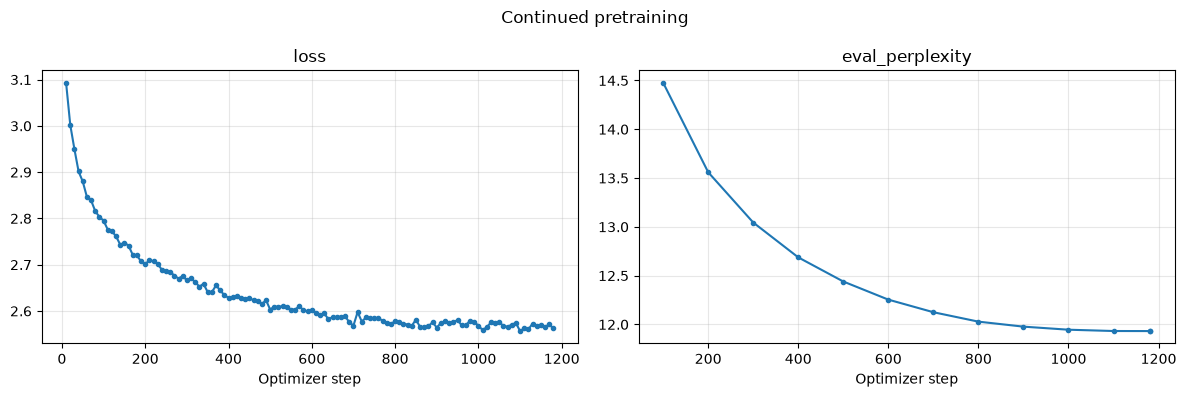

In [3]:
import mlflow
from src.plot import plot_run_metrics

experiment = mlflow.get_experiment_by_name(config.mlflow.experiment_name)
latest_full_run = mlflow.search_runs(
    [experiment.experiment_id],
    filter_string="tags.stage = 'pretrain' AND tags.run_type = 'full'",
    order_by=["start_time DESC"],
    max_results=1,
    output_format="list",
)[0]

plot_run_metrics(latest_full_run.info.run_id, ["loss", "eval_perplexity"])

## 6. Evaluate the pretrained model

Two questions, both against the original GPT-2:

- **PubMed perplexity**: did the model learn the biomedical domain?
- **MedText validation loss** (answer-only, as in `fpft.ipynb`): does pretraining on papers help, or hurt, the clinical question-answering format before any fine-tuning?

Both results are logged as MLflow evaluation runs.

In [8]:
from transformers import AutoTokenizer
from src.config import load_config
from src.dataset_preparation import load_medtext
from src.evaluation import evaluate
from src.formatting import to_sft_format
from src.modeling import load_model, resolve_model_source
from src.pretrain import evaluate_on_corpus
from src.tracking import log_evaluation

# Self-contained: recomputes the baseline so the cell also runs after a kernel restart
base_pubmed = evaluate_on_corpus(config.model.model_id, config)
pretrained_uri = f"models:/{config.mlflow.registered_model_name}@{config.pretraining.registry_alias}"
pretrained_pubmed = evaluate_on_corpus(pretrained_uri, config)
log_evaluation(pretrained_uri, "pubmed_validation", pretrained_pubmed, config)

sft_config = load_config("configs/gpt2_medtext.yaml")
_, medtext_validation, _ = load_medtext(sft_config.data.processed_dir)
medtext_validation = to_sft_format(medtext_validation)

medtext_loss = {}
for name, model_id in [("GPT-2 base", config.model.model_id), ("GPT-2 + PubMed", pretrained_uri)]:
    model, _ = load_model(model_id)
    model_tokenizer = AutoTokenizer.from_pretrained(resolve_model_source(model_id))
    medtext_loss[name] = evaluate(model, model_tokenizer, medtext_validation, sft_config)
    log_evaluation(model_id, "medtext_validation", {"loss": medtext_loss[name]}, config)

pd.DataFrame(
    {
        "PubMed perplexity": {
            "GPT-2 base": base_pubmed["perplexity"],
            "GPT-2 + PubMed": pretrained_pubmed["perplexity"],
        },
        "MedText validation loss": medtext_loss,
    }
).round(4)

Loading weights: 100%|██████████| 148/148 [00:00<00:00, 22072.14it/s]
[transformers] `loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


Training Loss,Validation Loss,Step
No log,2.883543,0


Loading weights: 100%|██████████| 148/148 [00:00<00:00, 20372.73it/s]


Training Loss,Validation Loss,Step
No log,2.479211,0


2026/11/02 19:04:47 INFO mlflow.system_metrics.system_metrics_monitor: Started monitoring system metrics.
2026/11/02 19:04:47 INFO mlflow.system_metrics.system_metrics_monitor: Stopping system metrics monitoring...
2026/11/02 19:04:47 INFO mlflow.system_metrics.system_metrics_monitor: Successfully terminated system metrics monitoring!
Loading weights: 100%|██████████| 148/148 [00:00<00:00, 20981.44it/s]


Device: cuda
Parameters: 124,439,808


... (3 outputs left out)

Device: cuda
Parameters: 124,439,808


Training Loss,Validation Loss,Step,Entropy,Mean Token Accuracy,Num Tokens
No log,2.720069,0,2.718969,0.450005,0.000000


2026/11/02 19:04:49 INFO mlflow.system_metrics.system_metrics_monitor: Started monitoring system metrics.
2026/11/02 19:04:49 INFO mlflow.system_metrics.system_metrics_monitor: Stopping system metrics monitoring...
2026/11/02 19:04:49 INFO mlflow.system_metrics.system_metrics_monitor: Successfully terminated system metrics monitoring!


,PubMed perplexity,MedText validation loss
GPT-2 base,17.8775,2.8858
GPT-2 + PubMed,11.9318,2.7201
